INFO: pip is looking at multiple versions of multiprocess to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 471.6/471.6 kB 34.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.8/134.8 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.1/194.1 kB 17.3 MB/s eta 0:00:00


/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


dogs-vs-cats-subset.zip:   0%|          | 0.00/90.8M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/4000 [00:00<?, ? examples/s]

/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 114MB/s]


Epoch [1/2], Loss: 0.0001
Epoch [2/2], Loss: 0.0000


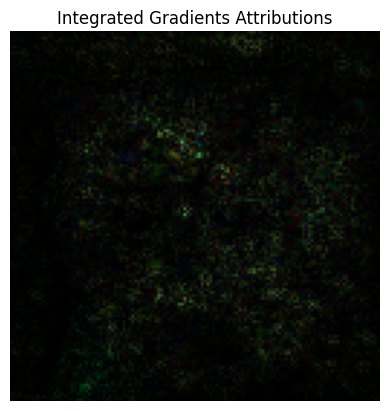

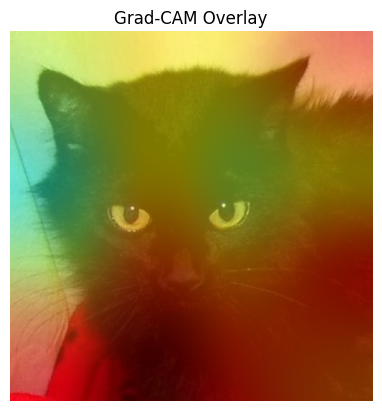

In [2]:
# Cats vs. Dogs Classification with Transfer Learning

#In this notebook, we will perform image classification on the Cats vs. Dogs dataset using a pre-trained ResNet model. We will also implement two explainability techniques: Integrated Gradients and Grad-CAM, to understand the model's decision-making process.

## 1. Setup and Import Libraries

#We will begin by installing and importing the necessary libraries.


# Install required libraries
!pip install torch torchvision captum datasets

# Import necessary libraries
import torch
import torchvision.transforms as transforms
from torchvision import models
import torch.nn as nn
import torch.optim as optim
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from captum.attr import IntegratedGradients, LayerGradCam
from datasets import load_dataset
from torch.utils.data import DataLoader

## 2. Load the Dataset

#We will use the Cats vs. Dogs dataset available from Hugging Face's `datasets` library.
#This dataset contains images of cats and dogs, and our goal is to classify them correctly.

# Load the Cats vs. Dogs dataset
dataset = load_dataset("pantelism/cats-vs-dogs")

## 3. Image Preprocessing

#We will define a function to preprocess the images. This includes resizing the images, converting them to tensors, and normalizing them.

def load_image(image):
    preprocess = transforms.Compose([
        transforms.Resize((128, 128)),  # Resize images to 128x128 pixels
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),  # Normalize the image
    ])
    image_tensor = preprocess(image).unsqueeze(0)  # Add batch dimension
    return image_tensor


## 4. Create Data Loader

#We'll create a custom dataset class to load images and labels, and then set up a DataLoader to manage our training data.

class CatsVsDogsDataset(torch.utils.data.Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset['train'])

    def __getitem__(self, idx):
        img = self.dataset['train'][idx]['image'].convert("RGB")
        label = 1 if 'dog' in self.dataset['train'][idx]['image'].filename else 0  # Labeling logic
        img_tensor = load_image(img)
        return img_tensor.squeeze(0), label  # Remove batch dimension

# Create DataLoader using a smaller subset for faster testing
small_dataset = dataset['train'].select(range(100))  # Adjust as needed
cats_vs_dogs_dataset = CatsVsDogsDataset({'train': small_dataset})
train_loader = DataLoader(cats_vs_dogs_dataset, batch_size=8, shuffle=True, num_workers=2, pin_memory=True)

## 5. Transfer Learning with ResNet

#We will load a pre-trained ResNet model, modify the final layer for our specific task, and prepare the model for training.

# Load a pre-trained model (e.g., ResNet)
model = models.resnet50(pretrained=True)

# Modify the final layer for 2 classes (cats vs. dogs)
num_classes = 2
model.fc = nn.Linear(model.fc.in_features, num_classes)

# Freeze earlier layers
for param in model.parameters():
    param.requires_grad = False  # Freeze all layers

# Unfreeze the final layer
for param in model.fc.parameters():
    param.requires_grad = True

# Set the model to training mode
model.train()

# Define a loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)


## 6. Training the Model

#We will run a simple training loop to train the model on our dataset.


# Training loop
num_epochs = 2  # Start with fewer epochs for testing
for epoch in range(num_epochs):
    for images, labels in train_loader:
        optimizer.zero_grad()  # Clear previous gradients
        outputs = model(images)  # Forward pass
        loss = criterion(outputs, labels)  # Compute loss
        loss.backward()  # Backward pass
        optimizer.step()  # Update weights

    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')

## 7. Model Evaluation

#After training, we will evaluate the model using Integrated Gradients and Grad-CAM to visualize the model's decision-making process.

# Switch to evaluation mode after training
model.eval()

# Example: Use the first image from the dataset for explanation
example_image = dataset['train'][0]['image'].convert("RGB")
input_image = load_image(example_image)

## 8. Integrated Gradients

### Explanation
#Integrated Gradients is a technique that attributes the model's output to its input features by integrating gradients along the path from a baseline to the input. It helps in understanding which pixels contributed most to the prediction.

### Compute Attributions

# Integrated Gradients
ig = IntegratedGradients(model)
baseline = torch.zeros(input_image.size()).to(input_image.device)

# Forward pass to get model output and class index
with torch.no_grad():
    output = model(input_image)
    target_class = output.argmax(dim=1).item()  # Get the predicted class index

# Compute attributions
attributions, _ = ig.attribute(input_image, target=target_class, baselines=baseline, return_convergence_delta=True)

# Visualize Integrated Gradients attributions
def visualize_attributions(attributions):
    attributions = attributions.squeeze().permute(1, 2, 0).detach().numpy()
    attributions = np.abs(attributions)  # Take absolute value
    plt.imshow(attributions, cmap='hot')
    plt.axis('off')
    plt.title('Integrated Gradients Attributions')
    plt.show()

visualize_attributions(attributions)

## 9. Grad-CAM

### Explanation
#Grad-CAM (Gradient-weighted Class Activation Mapping) is another technique that produces a heatmap of important regions in the input image for the predicted class. It uses the gradients of the class score with respect to the feature maps of the last convolutional layer to highlight the regions that influenced the decision.

### Compute Grad-CAM

# Grad-CAM
target_layer = model.layer4  # Adjust to your model's last convolutional layer
grad_cam = LayerGradCam(model, target_layer)

# Compute Grad-CAM
grayscale_cam = grad_cam.attribute(input_image, target=target_class)
grayscale_cam = grayscale_cam.squeeze().detach().numpy()

## 10. Overlay Grad-CAM on the Original Image

#We will overlay the Grad-CAM heatmap on the original image to visualize the important regions.

# Overlay Grad-CAM on the original image
def overlay_cam_on_image(original_image, grayscale_cam):
    original_size = original_image.size  # Get the original image size
    grayscale_cam = np.maximum(grayscale_cam, 0)  # ReLU
    grayscale_cam = grayscale_cam / grayscale_cam.max()  # Normalize
    heatmap = plt.cm.jet(grayscale_cam)[..., :3]  # Get RGB heatmap
    heatmap = Image.fromarray((heatmap * 255).astype(np.uint8))

    # Resize the heatmap to match the original image size
    heatmap = heatmap.resize(original_size, Image.LANCZOS)

    # Blend the original image with the heatmap
    overlay = Image.blend(original_image, heatmap, alpha=0.5)

    plt.imshow(overlay)
    plt.axis('off')
    plt.title('Grad-CAM Overlay')
    plt.show()

overlay_cam_on_image(example_image, grayscale_cam)







